# Paso 1 · Números complejos (con Python)

Notebook que acompaña a las diapositivas del **Paso 1**. Cada sección del notebook corresponde a un bloque de las diapositivas; el objetivo doble es:

1. **Matemático**: entender $j$, el plano complejo, forma rectangular y polar, producto y decibelios.
2. **De programación**: usar Python (tipos, funciones, vectorización con NumPy, `assert`, gráficos) como herramienta para *comprobar* cada cálculo.

> **Cómo usarlo.** Ejecuta las celdas en orden (`Mayús+Enter`). Las celdas marcadas **Tu turno** están incompletas a propósito. Las soluciones aparecen debajo, plegadas.
> Requisitos: `numpy` y `matplotlib`.

| Concepto matemático | Concepto de programación |
|---|---|
| $j$ y números complejos | tipo `complex`, `.real`, `.imag` |
| plano complejo | funciones con argumentos variables, `matplotlib` |
| rectangular ↔ polar | funciones propias, grados vs radianes |
| `atan` frente a `atan2` | bucles, f-strings, tablas de salida |
| producto en polar | `assert` y `np.isclose` como pruebas |
| decibelios | vectorización con arrays |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

## 1. ¿Qué es $j$?

$j$ es el número tal que $j^2=-1$. (En matemáticas se escribe $i$; en ingeniería de control se usa $j$ para no confundirlo con la corriente.)

**Python ya lo trae**: se escribe con un número delante y la letra `j` pegada: `1j`, `5j`, `2.5j`. Escribir `j` a secas es un nombre de variable, no el número imaginario.

In [2]:
j = 1j                      # guardamos el imaginario en una variable llamada j
print("j*j       =", j*j)
print("tipo      :", type(j))
z = 3 + 4j                  # un complejo: parte real 3, parte imaginaria 4
print("z         =", z)
print("z.real    =", z.real, "  z.imag =", z.imag)
print("conjugado =", z.conjugate())

j*j       = (-1+0j)
tipo      : <class 'complex'>
z         = (3+4j)
z.real    = 3.0   z.imag = 4.0
conjugado = (3-4j)


**Programación**: `complex` es un tipo numérico más, como `int` y `float`. Tiene atributos (`.real`, `.imag`) y métodos (`.conjugate()`). Una trampa habitual: `j` sin número delante da `NameError`, y `1+j` también (hay que escribir `1+1j`).

In [3]:
try:
    print(1 + k)            # k no está definida: Python no sabe qué es
except NameError as e:
    print("NameError:", e)

NameError: name 'k' is not defined


## 2. El plano complejo

Un número complejo $x+jy$ es un punto (o una flecha) del plano: $x$ en el eje horizontal (real) e $y$ en el vertical (imaginario).

Vamos a escribir una función que dibuje números complejos como flechas. Es nuestra primera **función con argumentos variables** (`*zs`): acepta cualquier número de complejos.

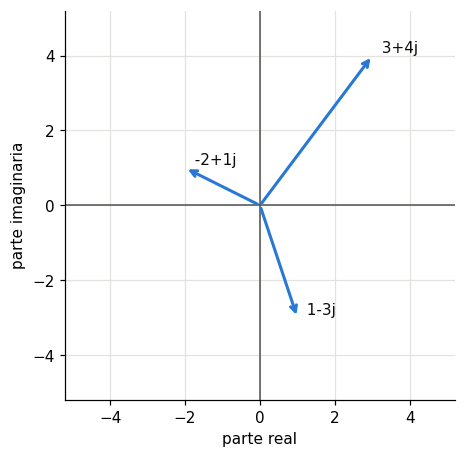

In [4]:
def dibujar_plano(*zs, etiquetas=None, ax=None):
    """Dibuja cada complejo de zs como una flecha desde el origen."""
    if ax is None:
        _, ax = plt.subplots(figsize=(4.6, 4.6))
    lim = 1.3 * max(max(abs(z.real), abs(z.imag)) for z in zs)
    for i, z in enumerate(zs):
        ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=AZUL, lw=2))
        txt = etiquetas[i] if etiquetas else f"{z:.3g}"
        ax.text(z.real, z.imag, "  " + txt, color=TINTA, va="bottom")
    ax.axhline(0, color=GRIS, lw=1); ax.axvline(0, color=GRIS, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("parte real"); ax.set_ylabel("parte imaginaria")
    return ax

dibujar_plano(3 + 4j, -2 + 1j, 1 - 3j)
plt.show()

## 3. Dos formas de escribir lo mismo: rectangular y polar

- **Rectangular**: $z=x+jy$.
- **Polar**: $z=r\angle\theta$, con $r=\sqrt{x^2+y^2}$ (magnitud) y $\theta$ (ángulo, la fase).

Python tiene `abs(z)` para la magnitud y `np.angle(z)` para el ángulo **en radianes**. Como en control se habla en grados, escribimos dos funciones de conversión. Escribir tus propias funciones pequeñas y *comprobarlas* es la mejor manera de no equivocarse con unidades.

In [5]:
def a_polar(z):
    """Rectangular -> (magnitud, ángulo en grados)."""
    return abs(z), np.degrees(np.angle(z))

def a_rect(r, grados):
    """Polar (magnitud, grados) -> complejo."""
    return r * np.exp(1j * np.radians(grados))

z = 5 + 5j
r, th = a_polar(z)
print(f"{z}  ->  {r:.3f} ∠ {th:.2f}°")
print("de vuelta:", a_rect(r, th))

(5+5j)  ->  7.071 ∠ 45.00°
de vuelta: (5.000000000000001+5j)


**Prueba automática.** `assert` falla con un error si algo no se cumple y no hace nada si se cumple. Para comparar decimales se usa `np.isclose` (nunca `==`, por los redondeos).

In [6]:
for z in [3+4j, -2+1j, 1-3j, -1-1j, 5+5j, 30+5j]:
    assert np.isclose(a_rect(*a_polar(z)), z), z
print("ida y vuelta correcta en", 6, "casos")

ida y vuelta correcta en 6 casos


## 4. `atan` frente a `atan2`: la trampa de los cuadrantes

La fórmula escolar $\theta=\arctan(y/x)$ solo devuelve ángulos entre $-90^\circ$ y $+90^\circ$: **no distingue** $(x,y)$ de $(-x,-y)$, porque el cociente es el mismo. La función `atan2(y, x)` mira por separado los signos de $y$ y de $x$, y da el cuadrante correcto. En NumPy: `np.arctan2(y, x)` (¡primero $y$!).

In [7]:
puntos = [(1, 1), (-1, 1), (-1, -1), (1, -1)]
print(f"{'(x, y)':>10} {'arctan(y/x)':>13} {'atan2(y,x)':>12}   ¿coinciden?")
for x, y in puntos:
    a = np.degrees(np.arctan(y / x))
    b = np.degrees(np.arctan2(y, x))
    print(f"{str((x, y)):>10} {a:>12.1f}° {b:>11.1f}°   {'sí' if np.isclose(a, b) else 'NO'}")

    (x, y)   arctan(y/x)   atan2(y,x)   ¿coinciden?
    (1, 1)         45.0°        45.0°   sí
   (-1, 1)        -45.0°       135.0°   NO
  (-1, -1)         45.0°      -135.0°   NO
   (1, -1)        -45.0°       -45.0°   sí


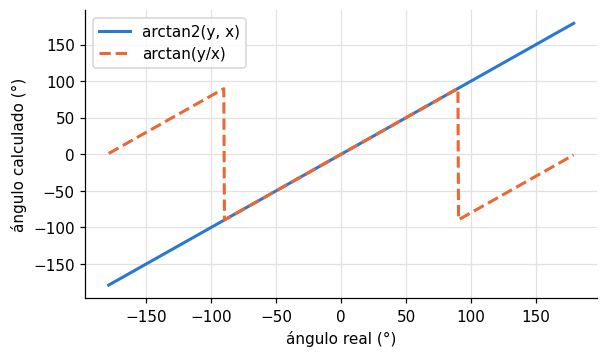

In [8]:
th = np.radians(np.linspace(-179, 179, 720))
x, y = np.cos(th), np.sin(th)
with np.errstate(divide="ignore"):
    ang_mala = np.degrees(np.arctan(y / x))
ang_buena = np.degrees(np.arctan2(y, x))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(np.degrees(th), ang_buena, color=AZUL, lw=2, label="arctan2(y, x)")
ax.plot(np.degrees(th), ang_mala, color=NARANJA, lw=2, ls="--", label="arctan(y/x)")
ax.set_xlabel("ángulo real (°)"); ax.set_ylabel("ángulo calculado (°)"); ax.legend()
plt.show()

La curva naranja se "dobla" en cuanto el punto pasa a los cuadrantes 2 y 3. Más adelante, cuando midamos la **fase** de $P(j\omega)$, usar `arctan` a secas daría fases erróneas. `np.angle(z)` ya usa `atan2` por dentro.

## 5. Operaciones

### Suma: en rectangular
Se suman partes reales por un lado y partes imaginarias por otro. En polar **no** se pueden sumar magnitudes y ángulos directamente.

In [9]:
a, b = 3 + 4j, 1 - 2j
print("suma rectangular:", a + b)
# trampa: sumar "a la polar" (magnitudes y ángulos por separado) NO es la suma
(ra, ta), (rb, tb) = a_polar(a), a_polar(b)
mal = a_rect(ra + rb, ta + tb)
print("suma 'polar' mal hecha:", np.round(mal, 3), "-> distinto de", a + b)

suma rectangular: (4+2j)
suma 'polar' mal hecha: (7.119-1.294j) -> distinto de (4+2j)


### Producto: en polar es más fácil
Magnitudes **se multiplican**, ángulos **se suman**: $(r_1\angle\theta_1)(r_2\angle\theta_2)=r_1r_2\angle(\theta_1+\theta_2)$. El cociente: magnitudes se dividen y ángulos se restan.

Comprobamos con el código que **las dos vías dan lo mismo** (la distributiva en rectangular y la regla polar):

In [10]:
def producto_polar(z1, z2):
    (r1, t1), (r2, t2) = a_polar(z1), a_polar(z2)
    return r1 * r2, t1 + t2

def cociente_polar(z1, z2):
    (r1, t1), (r2, t2) = a_polar(z1), a_polar(z2)
    return r1 / r2, t1 - t2

z1, z2 = 5 + 5j, 30 + 5j
rect = z1 * z2                       # Python hace la distributiva por nosotros
r, t = producto_polar(z1, z2)
print("rectangular :", rect)
print(f"polar       : {r:.2f} ∠ {t:.2f}°")
assert np.isclose(a_rect(r, t), rect)

r, t = cociente_polar(z1, z2)
assert np.isclose(a_rect(r, t), z1 / z2)
print("producto y cociente: las dos vías coinciden")

rectangular : (125+175j)
polar       : 215.06 ∠ 54.46°
producto y cociente: las dos vías coinciden


## 6. Ejemplo resuelto del curso: $P(j5)$

Planta nominal $P(s)=\dfrac{k}{(s+a)(s+b)}$ con $k=1,\ a=5,\ b=30$. Queremos $P(j\omega)$ en $\omega=5$ rad/s. Sustituimos $s=j\omega$:

$$P(j5)=\frac{1}{(5+5j)(30+5j)}$$

**Tu turno 1.** Calcula a mano (o en la celda) el denominador por la vía rectangular, como en las diapositivas: debe salir $125+175j$.

In [11]:
# TU TURNO: completa el producto (5+5j)(30+5j) usando la distributiva a mano,
# sin escribir z1*z2: calcula parte real y parte imaginaria por separado.
real = 0                 # sustituye por: 5*30 + (5j)(5j) = ...
imag = 0                 # sustituye por: 5*5 + 5*30
den = complex(real, imag)
print(den)               # debe ser (125+175j)

0j


In [12]:
real = 5*30 + (5*5)*(-1)      # j*j = -1
imag = 5*5 + 5*30
den = complex(real, imag)
print(den)
assert den == (5+5j)*(30+5j)

(125+175j)


Ahora la función completa, que usaremos en toda la serie: una **función de $\omega$** que devuelve el complejo $P(j\omega)$.

In [13]:
def P(w, k=1, a=5, b=30):
    """Planta k/((s+a)(s+b)) evaluada en s = j*w."""
    s = 1j * w
    return k / ((s + a) * (s + b))

p5 = P(5)
r, t = a_polar(p5)
print("P(j5) =", p5)
print(f"      = {r:.5f} ∠ {t:.2f}°")
print(f"magnitud en dB: {20*np.log10(r):.2f} dB")

P(j5) = (0.002702702702702703-0.0037837837837837837j)
      = 0.00465 ∠ -54.46°
magnitud en dB: -46.65 dB


La planta tiene dos polos, así que el ángulo de $P$ es **menos** la suma de los ángulos de los factores: $-(45^\circ+9.46^\circ)=-54.46^\circ$. Es el resultado de las diapositivas.

## 7. El logaritmo y los decibelios

Multiplicar es incómodo y sumar es cómodo. El logaritmo convierte lo primero en lo segundo: $\log(ab)=\log a+\log b$. En control se usan los **decibelios**:

$$|P|_{\mathrm{dB}}=20\log_{10}|P|$$

Así, el producto de magnitudes pasa a ser una **suma de dB**. Lo comprobamos con los factores del ejemplo:

In [14]:
db = lambda z: 20 * np.log10(np.abs(z))

f1, f2 = 5 + 5j, 30 + 5j
print(f"|f1| = {abs(f1):7.3f}  ->  {db(f1):6.2f} dB")
print(f"|f2| = {abs(f2):7.3f}  ->  {db(f2):6.2f} dB")
print(f"|f1·f2| en dB = {db(f1*f2):.2f}   y   suma de dB = {db(f1)+db(f2):.2f}")
assert np.isclose(db(f1*f2), db(f1) + db(f2))
print("El producto se ha convertido en una suma.")

# P(j5) tiene el denominador en el denominador: los dB RESTAN
print(f"|P(j5)| = {db(P(5)):.2f} dB = -({db(f1):.2f}) - ({db(f2):.2f})")

|f1| =   7.071  ->   16.99 dB
|f2| =  30.414  ->   29.66 dB
|f1·f2| en dB = 46.65   y   suma de dB = 46.65
El producto se ha convertido en una suma.
|P(j5)| = -46.65 dB = -(16.99) - (29.66)


Y la gráfica que lo explica: el logaritmo "comprime" los números grandes y "estira" los pequeños.

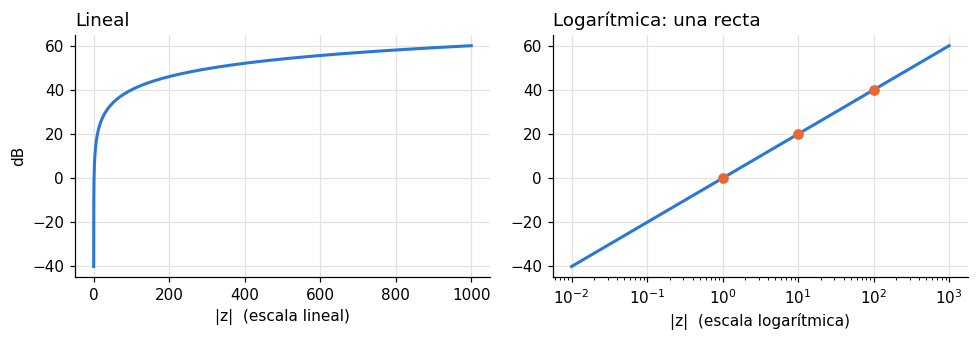

Factor 10 en magnitud = 20 dB;  factor 2 ≈ 6 dB;  factor √2 ≈ 3 dB
  × 10.000  ->   20.00 dB
  ×  2.000  ->    6.02 dB
  ×  1.414  ->    3.01 dB
  ×100.000  ->   40.00 dB
  ×  0.100  ->  -20.00 dB


In [15]:
x = np.logspace(-2, 3, 400)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(x, 20*np.log10(x), color=AZUL, lw=2)
ax[0].set_xlabel("|z|  (escala lineal)"); ax[0].set_ylabel("dB"); ax[0].set_title("Lineal", loc="left")
ax[1].semilogx(x, 20*np.log10(x), color=AZUL, lw=2)
ax[1].set_xlabel("|z|  (escala logarítmica)"); ax[1].set_title("Logarítmica: una recta", loc="left")
for v, c in [(1, GRIS), (10, GRIS), (100, GRIS)]:
    ax[1].plot(v, 20*np.log10(v), "o", color=NARANJA)
plt.tight_layout(); plt.show()
print("Factor 10 en magnitud = 20 dB;  factor 2 ≈ 6 dB;  factor √2 ≈ 3 dB")
for f in (10, 2, np.sqrt(2), 100, 0.1):
    print(f"  ×{f:7.3f}  ->  {20*np.log10(f):6.2f} dB")

## 8. Un adelanto: de un punto a muchos (vectorización)

Con `np.logspace` y arrays, la misma función `P` se evalúa en muchas frecuencias **de una sola vez**, sin bucles. Es la base del Paso 3 (respuesta en frecuencia) y de todo el código QFT de los pasos 16–18.

In [16]:
w = np.array([0.1, 1, 5, 10, 30, 100, 1000])
z = P(w)                       # P acepta arrays porque solo usa operaciones de NumPy
print(f"{'w':>7} {'|P|':>12} {'dB':>8} {'fase':>9}")
for wi, zi in zip(w, z):
    print(f"{wi:>7g} {abs(zi):>12.3e} {db(zi):>8.2f} {np.degrees(np.angle(zi)):>8.2f}°")

      w          |P|       dB      fase
    0.1    6.665e-03   -43.52    -1.34°
      1    6.534e-03   -43.70   -13.22°
      5    4.650e-03   -46.65   -54.46°
     10    2.828e-03   -50.97   -81.87°
     30    7.750e-04   -62.21  -125.54°
    100    9.566e-05   -80.39  -160.44°
   1000    9.995e-07  -120.00  -178.00°


Esta es la tabla del barrido a mano del Paso 3, ahora producida por una línea de código.

## 9. Trampas habituales

1. **`np.sqrt(-1)` da `nan`**; hay que darle un complejo: `np.sqrt(-1+0j)`.
2. **Comparar con `==`**: los decimales acumulan error; usar `np.isclose`.
3. **Grados y radianes**: `np.angle` devuelve radianes. Si olvidas `np.degrees`, un ángulo de $1.2$ puede ser $1.2^\circ$ o $69^\circ$.
4. **Fase de un producto = suma** pero **fase de $1/z$ = $-$ fase de $z$**.

In [17]:
print("np.sqrt(-1)       ->", np.sqrt(-1 + 0j), "(con +0j)")
print("0.1+0.2 == 0.3    ->", 0.1 + 0.2 == 0.3, "   np.isclose ->", np.isclose(0.1 + 0.2, 0.3))
z = 1 + 1j
print("np.angle(z)       ->", np.angle(z), "rad  =", np.degrees(np.angle(z)), "°")
print("fase(1/z)         ->", np.degrees(np.angle(1/z)), "°  (es -fase(z))")

np.sqrt(-1)       -> 1j (con +0j)
0.1+0.2 == 0.3    -> False    np.isclose -> True
np.angle(z)       -> 0.7853981633974483 rad  = 45.0 °
fase(1/z)         -> -45.0 °  (es -fase(z))


## 10. Ejercicio del Paso 1: $P(j10)$

Calcula $P(j10)$ para $k=1,\ a=5,\ b=30$:

1. Los dos factores del denominador: $j\omega+a$ y $j\omega+b$ con $\omega=10$.
2. Pásalos a polar (magnitud y ángulo).
3. Multiplícalos en polar y calcula $P(j10)=1/(\cdots)$.
4. Da el resultado en **dB** y en **grados**.
5. Compruébalo multiplicando en rectangular.

**Tu turno 2.**

In [18]:
w = 10
# f1 = ...   (jw + a)
# f2 = ...   (jw + b)
# r1, t1 = a_polar(f1) ...
# resultado en dB y grados: escribe aquí tu código

In [19]:
w = 10
f1, f2 = 1j*w + 5, 1j*w + 30
(r1, t1), (r2, t2) = a_polar(f1), a_polar(f2)
print(f"f1 = {r1:.3f} ∠ {t1:.2f}°     f2 = {r2:.3f} ∠ {t2:.2f}°")
r_den, t_den = r1 * r2, t1 + t2
print(f"denominador = {r_den:.3f} ∠ {t_den:.2f}°")
mag, fase = 1 / r_den, -t_den
print(f"P(j10) = {mag:.5f} ∠ {fase:.2f}°   =>   {20*np.log10(mag):.2f} dB, {fase:.2f}°")
# comprobación en rectangular
assert np.isclose(1 / (f1 * f2), P(10)) and np.isclose(a_rect(mag, fase), P(10))
print("coincide con P(10) calculado directamente:", P(10))

f1 = 11.180 ∠ 63.43°     f2 = 31.623 ∠ 18.43°
denominador = 353.553 ∠ 81.87°
P(j10) = 0.00283 ∠ -81.87°   =>   -50.97 dB, -81.87°
coincide con P(10) calculado directamente: (0.00039999999999999996-0.0028j)


## 11. Resumen

- `1j` es $j$; los complejos son un tipo más de Python (`.real`, `.imag`, `abs`, `np.angle`).
- Rectangular para **sumar**, polar para **multiplicar y dividir**; en decibelios el producto es una **suma**.
- Usa `np.arctan2` (o `np.angle`), nunca `arctan(y/x)`, para el ángulo.
- Funciones pequeñas + `assert`/`np.isclose` = cada cálculo a mano queda **comprobado**.
- `P(w)` escrita con operaciones de NumPy sirve para un número o para un array entero: es la idea que sostendrá el resto del curso.

**Siguiente:** Paso 2, funciones de transferencia, polos y ceros.